# 03. Modeling: churn driver diagnostic

**Question.** Which customers are most likely to leave, how well can we rank them, and which of the drivers could the business act on?

**Plan, in order:** validation design, baselines, model family comparison, Optuna tuning, model selection, one-touch held-out evaluation, explanation and what-if analysis, artifacts, model card.

**Reading guide.** Every analytical step has an explanation cell before it (why this method, alternatives, how it works, how to read the output) and a note after it that says what the output showed. Decision rules are written before results.

**What the model cannot do.** It ranks customers by how much they look like past leavers. It does not say why anyone left, and a feature that predicts churn is not automatically a lever that reduces it.

## 1. Setup and data

Plain words: load the feature table written by notebook 02 and keep only the training rows for now. The held-out test rows are loaded once, in section 7. Print the library versions and the seed so the run can be repeated.

In [1]:
import os, sys, json, time, warnings, subprocess
warnings.filterwarnings('ignore')
PROJECT = os.path.abspath('..'); sys.path.insert(0, os.path.join(PROJECT, 'src'))
import numpy as np, pandas as pd, sklearn, scipy, matplotlib, optuna, lightgbm, xgboost, catboost, shap, joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import features as F, model_utils as M
SEED = F.SEED; np.random.seed(SEED)
CH = f'{PROJECT}/reports/modeling/charts'; TB = f'{PROJECT}/reports/modeling/tables'
for d in (CH, TB, f'{PROJECT}/models'): os.makedirs(d, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
print('seed', SEED, '| sklearn', sklearn.__version__, '| lightgbm', lightgbm.__version__, '| xgboost', xgboost.__version__,
      '| catboost', catboost.__version__, '| optuna', optuna.__version__, '| shap', shap.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)
df = M.load_features(); FL = M.load_feature_list(); kept = FL['kept']
train = df[df['split'] == 'train'].reset_index(drop=True)
Xtr = train.drop(columns=[F.ID_COL, 'split', F.TARGET]); ytr = train[F.TARGET]
print('training rows', len(train), '| leavers', int(ytr.sum()), f'({100*ytr.mean():.1f}%) | engineered features kept:', kept)

seed 42 | sklearn 1.9.1 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | optuna 5.0.0 | shap 0.54.1 | pandas 2.3.3 | numpy 2.4.6
training rows 5634 | leavers 1495 (26.5%) | engineered features kept: ['contract_ord', 'm2m_fiber', 'm2m_echeck', 'm2m_first_year', 'first_year', 'log_tenure', 'internet_no_techsupport', 'internet_no_protection', 'n_protection', 'household_size']


**What the output shows.** The training split has 5,634 customers, 1,495 of them leavers (26.5%). Ten engineered features survived the checks in notebook 02 (`price_resid` and `n_streaming` were dropped for showing no steady link to churn). The test rows have not been loaded yet. Library versions and the seed (42) are printed so the run can be repeated.

## 2. Validation design

**Repeated stratified 5-fold cross-validation on the training rows, with a held-out test set touched once**

1. **Why this method.** We need an honest estimate of how the model will do on customers it has not seen, and we need to choose between models without using the test set. The handoff gives the design: one row per customer (rows independent, no grouping needed) and no date (no time split). A fixed 20% test set (1,409 customers) stays locked until section 7.
2. **Alternatives considered.**
   - Single train/validation split: cheap, but with about 1,500 leavers in training one split gives a noisy score. Not used.
   - Group k-fold by customer or out-of-time split: not applicable here (one row per customer, no date).
   - Leave-one-out: nearly unbiased but expensive and high-variance for ranking metrics. Not used.
3. **How it works.** Cross-validation (CV) cuts the training rows into 5 parts that each keep 26.5% leavers (stratified). Each part is scored by a model trained on the other four. The cut is repeated 5 times with different shuffles, giving 25 scores per model. We report their mean and standard deviation (SD, the spread). All preprocessing (one-hot coding, scaling, any fitted feature) sits inside a scikit-learn Pipeline, which is refitted on the training part of every fold, so nothing is learned from the validation part. **Primary ranking metric:** AUC (area under the ROC curve: the chance a random leaver gets a higher score than a random stayer; 0.5 is a coin flip, 1.0 is perfect), $AUC=P(s_i>s_j\mid y_i=1,y_j=0)$. **Business metric:** top-20% revenue capture = (monthly bills of leavers inside the 20% of customers with the highest score) / (monthly bills of all leavers); a random ranking gives 20%, the explorer's rule gave about 52% in-sample. **Also recorded:** PR-AUC (average precision: how pure the flagged group stays as we flag more; the leaver base rate 0.265 is the no-skill level), Brier score ($\frac1n\sum(\hat p_i-y_i)^2$; 0 is perfect, always guessing 0.265 gives about 0.195) and ECE (expected calibration error: the average gap between predicted and actual churn rate across 10 probability bins; under 0.05 is a useful target). Decision rules, fixed before any result: models are compared on AUC; ties are read together with top-20% capture and Brier; in section 4 (untuned comparison) and in notebook 02 a model counts as better only if its mean exceeds the other by more than the SD of the paired fold differences. Section 6 uses a different, simpler band for the tuned families, explained there, because paired differences between tuned families were not computed.
4. **How to read the output.** Look at the fold sizes: each validation part should have a similar leaver count. An SD larger than the gap between two models means the models cannot be told apart on this data.

In [2]:
splits = M.repeated_splits(ytr, 5, 5)            # 25 (train_idx, validation_idx) pairs, same for every model
cnt = pd.DataFrame([dict(fold=i, train_rows=len(a), valid_rows=len(b), valid_leavers=int(ytr.iloc[b].sum()), valid_rate_pct=round(100*ytr.iloc[b].mean(), 2)) for i, (a, b) in enumerate(splits)])
display(cnt.describe().loc[['min', 'max']].round(2))
print('number of fold-scores per model:', len(splits))

,fold,train_rows,valid_rows,valid_leavers,valid_rate_pct
min,0.0,4507.0,1126.0,299.0,26.53
max,24.0,4508.0,1127.0,299.0,26.55


number of fold-scores per model: 25


**What the output shows.** There are 25 fold-scores per model. Every validation part holds 1,126 or 1,127 customers and 299 leavers (26.5%), so the folds are balanced and the same for every model. A metric difference between two models is therefore not caused by one model getting an easier fold.

## 3. Baselines: the floor to beat

**Two business rules and a plain regularised logistic regression on the raw columns**

1. **Why this method.** A model is only useful if it beats what a manager could do without it. Rule 1 is the simplest heuristic: flag month-to-month fiber customers in their first 12 months (finding 5). Rule 2 is the explorer's ranking: the churn rate of each contract x internet x first-year segment, learned on the training part of each fold. The logistic model on raw columns sets the floor for statistical modelling.
2. **Alternatives considered.**
   - Rank by a single column (for example contract only): even simpler, but the segment rule already contains it.
   - Rank by MonthlyCharges: tests the idea that big bills churn, but H6 shows the link is only moderate.
   - A decision tree of depth 3: a rule found by data, but it is close to Rule 2 and less stable.
3. **How it works.** Rule 1 scores 1 for the flagged group and 0 for everyone else. Rule 2 scores each segment with $\hat p_g=\frac{k_g+m\,\bar y}{n_g+m}$, where $k_g$ is the number of leavers and $n_g$ the customers of segment $g$ in the training part, $\bar y$ the overall churn rate and $m=20$ pseudo-customers that pull small segments toward the average. Logistic regression models the log-odds of leaving as a weighted sum of the inputs, $\log\frac{p}{1-p}=b_0+\sum_j b_jx_j$, with an L2 penalty (a pull that shrinks every weight toward zero so no single column dominates; strength set by C, here the default 1.0). Categorical columns are one-hot coded (one 0/1 column per category) and numbers are standardised, both inside the pipeline. Ties in rule scores are broken at random with a fixed seed, so the top-20% group is well defined.
4. **How to read the output.** Compare the AUC, top-20% revenue capture and Brier of each baseline. Rule 1 gives only two score values, so its AUC and ECE are crude and its calibration is not meaningful. Whatever the best baseline achieves is the number the tuned models must beat.

In [3]:
results = {}     # name -> per-fold DataFrame
def run(name, est, X=None):
    results[name] = M.cv_evaluate(est, Xtr if X is None else X, ytr, splits)
    return results[name]
run('Rule 1: m2m fiber first-year flag', M.RuleFlag())
run('Rule 2: segment churn rate', M.RuleSegmentRate(m=20))
run('Logistic regression, raw columns', M.make_pipeline('glm', feature_set='raw'))
COLS = ['auc', 'pr_auc', 'top20_rev', 'top20_precision', 'brier', 'ece']
def table(names):
    rows = []
    for n in names:
        r = results[n]; row = {'model': n}
        for c in COLS: row[c + ' mean'] = r[c].mean(); row[c + ' sd'] = r[c].std()
        row['fit s'] = r['fit_s'].mean(); rows.append(row)
    return pd.DataFrame(rows)
base_tbl = table(list(results)); display(base_tbl.round(4))
base_tbl.to_csv(f'{TB}/baselines_cv.csv', index=False)

,model,auc mean,auc sd,pr_auc mean,pr_auc sd,top20_rev mean,top20_rev sd,top20_precision mean,top20_precision sd,brier mean,brier sd,ece mean,ece sd,fit s
0,Rule 1: m2m fiber first-year flag,0.6485,0.0116,0.4212,0.0160,0.4384,0.0259,0.5333,0.0267,0.2103,0.0069,0.2103,0.0069,0.0006
1,Rule 2: segment churn rate,0.8217,0.0115,0.5702,0.0182,0.5220,0.0363,0.6131,0.0221,0.1425,0.0038,0.0225,0.0089,0.0022
2,"Logistic regression, raw columns",0.8444,0.0101,0.6599,0.0172,0.5659,0.0210,0.6766,0.0226,0.1355,0.0039,0.0264,0.0082,0.0170


**What the output shows.** Rule 1 (flag month-to-month fiber customers in year one) ranks poorly: AUC 0.649 and 43.8% of lost revenue in the top 20% (random would give 20%). Rule 2 (segment churn rate) reaches AUC 0.822 (SD 0.012) and 52.2% capture (SD 3.6 points), which agrees with the explorer's in-sample 52%, so that rule holds up on unseen folds. The raw-column logistic regression is the floor to beat: AUC 0.844 (SD 0.010), PR-AUC 0.660, top-20% capture 56.6% (SD 2.1 points), Brier 0.1355 (always guessing the base rate gives about 0.195). Rule 1 has only two score values, so its ECE of 0.21 is not meaningful.

## 4. Model family comparison

**Five model families, same folds, engineered features**

1. **Why this method.** Different families capture different shapes: straight-line effects, interactions, thresholds. With 5,634 training customers and about 28 inputs, we expect small differences, so the comparison also tests whether a simple model is enough.
2. **Alternatives considered.**
   - Fit only one favourite family (for example LightGBM): fast, but we could not show that a simpler or different family is not better.
   - Add neural networks or stacked ensembles: more flexible, but for 5,600 rows of mostly 0/1 inputs they rarely beat boosting and they cost explainability. Not used.
   - Compare on a single split: noisy; the 25-fold design above is more stable.
3. **How it works.** **Regularised logistic regression (GLM, generalised linear model)**: a weighted sum of inputs turned into a probability; the L2 penalty shrinks weights; C controls strength (smaller C, stronger shrinkage). **Random forest**: many deep decision trees, each fit on a random resample of rows and a random subset of columns, averaged; averaging cancels their individual overfitting; main knobs are tree depth, minimum leaf size and columns tried per split. **LightGBM, XGBoost, CatBoost (gradient boosting)**: trees fitted one after another, each correcting the errors of the sum so far, $F_m(x)=F_{m-1}(x)+\eta\,h_m(x)$, where $h_m$ is the new small tree and $\eta$ the learning rate; they avoid overfitting through a small $\eta$, shallow trees, minimum rows per leaf, row and column sampling and an L2 penalty on leaf values. CatBoost uses symmetric trees and ordered boosting, which is steadier on small data. All five receive the same one-hot coded inputs and the same 25 folds. Decision rule, fixed before the result: **the three families with the highest mean CV AUC go to Optuna tuning.**
4. **How to read the output.** Read AUC and top-20% capture with their SDs. Differences smaller than the SD are noise. The chart shows mean with one SD whiskers.

GLM (logistic, engineered): 0s


Random forest: 5s


LightGBM: 1s


XGBoost: 1s


CatBoost: 3s


,model,auc mean,auc sd,pr_auc mean,pr_auc sd,top20_rev mean,top20_rev sd,top20_precision mean,top20_precision sd,brier mean,brier sd,ece mean,ece sd,fit s
0,"GLM (logistic, engineered)",0.8501,0.0092,0.6731,0.0219,0.5543,0.0202,0.6827,0.0248,0.1329,0.0039,0.0243,0.0049,0.0184
1,Random forest,0.8458,0.0103,0.6612,0.0237,0.5440,0.0204,0.6671,0.0226,0.1349,0.0042,0.0270,0.0071,0.9331
2,LightGBM,0.8443,0.0098,0.6644,0.0220,0.5456,0.0180,0.6687,0.0216,0.1356,0.0043,0.0313,0.0068,0.1059
3,XGBoost,0.8481,0.0094,0.6692,0.0220,0.5523,0.0183,0.6779,0.0230,0.1339,0.0039,0.0277,0.0061,0.1053
4,CatBoost,0.8447,0.0098,0.6628,0.0204,0.5425,0.0212,0.6660,0.0236,0.1356,0.0042,0.0304,0.0080,0.5129
5,"Logistic regression, raw columns",0.8444,0.0101,0.6599,0.0172,0.5659,0.0210,0.6766,0.0226,0.1355,0.0039,0.0264,0.0082,0.0170
6,Rule 2: segment churn rate,0.8217,0.0115,0.5702,0.0182,0.5220,0.0363,0.6131,0.0221,0.1425,0.0038,0.0225,0.0089,0.0022


families ranked by mean CV AUC: ['glm', 'xgb', 'rf', 'catboost', 'lgbm'] 
-> tuned: ['glm', 'xgb', 'rf']


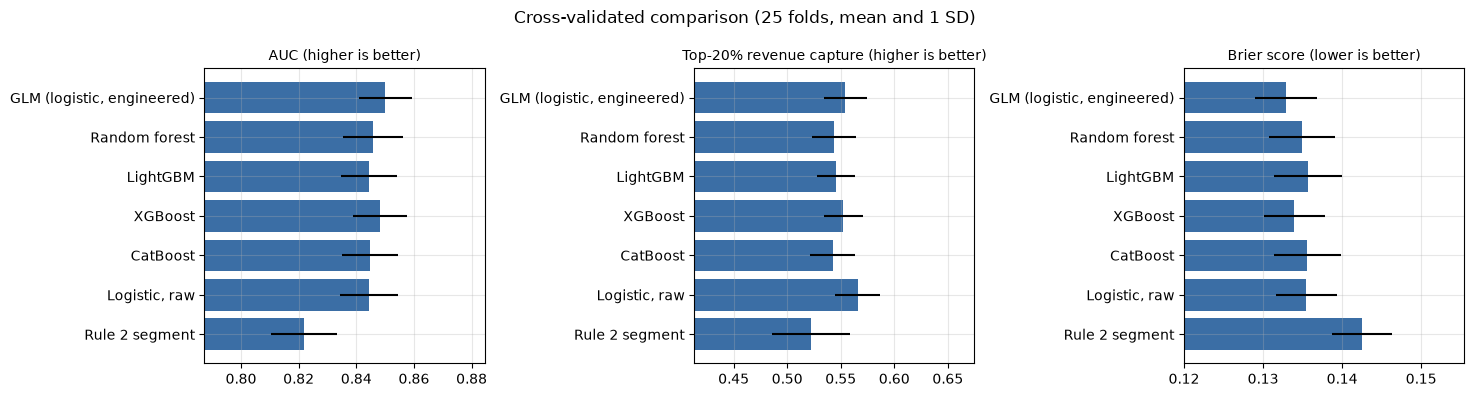

In [4]:
fam_names = {'glm': 'GLM (logistic, engineered)', 'rf': 'Random forest', 'lgbm': 'LightGBM', 'xgb': 'XGBoost', 'catboost': 'CatBoost'}
for f, nm in fam_names.items():
    t0 = time.time(); run(nm, M.make_pipeline(f, feature_set='eng', kept=kept)); print(f'{nm}: {time.time()-t0:.0f}s')
fam_tbl = table(list(fam_names.values()) + ['Logistic regression, raw columns', 'Rule 2: segment churn rate']).round(4)
display(fam_tbl)
fam_tbl.to_csv(f'{TB}/family_comparison_cv.csv', index=False)
ranked = sorted(fam_names, key=lambda f: -results[fam_names[f]]['auc'].mean())
top3 = ranked[:3]; print('families ranked by mean CV AUC:', ranked, '\n-> tuned:', top3)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
labs = list(fam_names.values()) + ['Logistic, raw', 'Rule 2 segment']; keys = list(fam_names.values()) + ['Logistic regression, raw columns', 'Rule 2: segment churn rate']
for a, (c, ttl) in zip(ax, [('auc', 'AUC (higher is better)'), ('top20_rev', 'Top-20% revenue capture (higher is better)'), ('brier', 'Brier score (lower is better)')]):
    m = [results[k][c].mean() for k in keys]; s = [results[k][c].std() for k in keys]
    a.barh(labs, m, xerr=s, color='#3b6ea5'); a.set_title(ttl, fontsize=10); a.invert_yaxis()
    lo = min(m) - 3*max(s); a.set_xlim(max(0, lo), max(m) + 3*max(s))
plt.suptitle('Cross-validated comparison (25 folds, mean and 1 SD)'); plt.tight_layout(); plt.savefig(f'{CH}/model_comparison.png', dpi=110); plt.show()

**What the output shows.** All families sit within about one SD (0.009 to 0.010) of one another. Mean AUC: GLM on engineered features 0.850, XGBoost 0.848, random forest 0.846, CatBoost 0.845, LightGBM 0.844, raw logistic 0.844. So tree models do not beat the straight-line model on this data; the joint effects they could find were already given to the GLM as features. Top-20% capture is 54 to 55% for every engineered-feature model and 56.6% for the raw logistic, a difference inside the 2-point SD, so no family is shown better on the business metric. By the rule, the three highest are tuned: GLM, XGBoost and random forest. LightGBM and CatBoost ranked fourth and fifth by under 0.002 AUC, which is noise.

## 5. Optuna tuning with nested cross-validation

**Tune the top three families with Optuna, scored by nested cross-validation**

1. **Why this method.** Default settings are rarely the best settings, but tuning on the same folds you report from gives an optimistic score, because the best of many trials is partly luck. Nested CV keeps the estimate honest: parameters are always chosen on rows that the scoring part has never seen.
2. **Alternatives considered.**
   - Grid search: tries every combination on a fixed grid; wastes trials on poor regions and grows too fast with more parameters.
   - Random search: simple and decent; TPE (below) usually finds good settings in fewer trials by learning from past ones.
   - Skip tuning and keep defaults: the comparison in section 4 already shows how close defaults are; tuning checks whether there is anything left to gain.
3. **How it works.** **Sampler:** TPE (Tree-structured Parzen Estimator): after 10 random start trials it models which parameter values gave good scores and which gave poor ones, and samples more from the good region. Seed fixed to 42 (outer fold k uses 42+k). **Pruner:** median pruner: after each inner fold the trial's running mean AUC is compared with the median of earlier trials at the same step, and the trial stops early if it is below (10 start trials, no pruning on the first fold). Median pruning suits 3-fold inner CV because there are only 3 checkpoints per trial: a rule based on the median of earlier trials needs no tuning, never stops a trial before it has seen one fold, and cannot be fooled by a noisy single fold as a stricter rule (for example stopping at the best-so-far) could. It saves time without removing the good region, because only trials below the median after the first or second fold are stopped. **Objective:** mean AUC over the inner folds. We optimise AUC (the ranking metric) because the ranking is what the retention list is built from; for every trial we also store top-20% revenue capture, PR-AUC, Brier and fit time, so the final choice weighs all of them. **Nested design (two levels):** (1) Outer loop, honest estimate: the 5,634 training rows are cut into 5 outer folds. For each, a separate study of 60 trials tunes on the outer-training rows with 3-fold inner CV, then the best parameters are refitted on all outer-training rows and scored once on the outer-validation rows. The mean and SD of those 5 scores is the nested estimate. (2) Final study: one study of 60 trials on 5-fold CV of the whole training set; its best parameters are the ones used for the final model. It is saved to `models/optuna_<family>.db`. Time cap 15 minutes per study (30 per family); in practice all studies finish all 60 trials. **Search spaces** are shown below with the reason for each range. Ranges are wide enough to include the defaults and narrow enough that small data cannot be overfitted by deep trees.
4. **How to read the output.** The key number is the nested outer-fold AUC (mean and SD). The final-study best AUC will be a little higher, because it is the best of 60 trials on the same folds that picked it; the gap between the two shows how much of the tuning gain was luck. The importance table says which parameters mattered; low importance across the board means the family is insensitive to tuning.

In [5]:
rows = []
for f in top3:
    for p, rng, why in M.SEARCH_SPACE_TEXT[f]: rows.append({'family': f, 'parameter': p, 'range': rng, 'why this range': why})
space_tbl = pd.DataFrame(rows); space_tbl.to_csv(f'{TB}/optuna_search_space.csv', index=False); display(space_tbl)

,family,parameter,range,why this range
0,glm,C,log 0.001 to 10,inverse penalty strength; log scale because us...
1,glm,l1_ratio,0 to 1,mix of ridge (0) and lasso (1) penalty; lasso ...
2,xgb,n_estimators,100 to 600 step 50,number of boosting rounds
3,xgb,learning_rate,log 0.01 to 0.2,step size
4,xgb,max_depth,2 to 7,tree depth; small data wants shallow trees
5,xgb,min_child_weight,log 1 to 30,minimum summed weight in a leaf; guards agains...
6,xgb,subsample,0.5 to 1.0,share of rows per round
7,xgb,colsample_bytree,0.4 to 1.0,share of columns per tree
8,xgb,reg_lambda,log 0.01 to 30,L2 penalty on leaf values
9,rf,n_estimators,200 to 600 step 100,more trees steady the average; gains stop early


**What the output shows.** The search spaces: 2 parameters for the GLM, 7 for XGBoost, 4 for the random forest, each with the reason for its range. Ranges include the default values used in section 4.

### 5.2 Tune family number 1 of the top three (chosen in section 4)
**What is different about this family (in this run family 1 is the GLM).** GLM: the two searched numbers decide how much the weights are shrunk. C (log scale, 0.001 to 10) covers from near-constant predictions to almost no shrinkage; l1_ratio (0 to 1) moves between ridge and lasso. This suits a linear model, whose only real freedom is penalty strength and type. Look for: a best C at the top edge of the range (10) would mean the data wants even less shrinkage than allowed; a score barely above the section 4 default means the family has nothing left to tune.

Plain words: run the nested study for the family ranked 1 in section 4. The result is cached in `models/tuning_<family>.json` and `models/optuna_<family>.db`, so re-running the notebook reloads it instead of tuning again. The table lists the five outer folds: each row is the score of parameters tuned without seeing that fold.

In [6]:
fam = top3[0]; t0 = time.time()
tuned = globals().setdefault('tuned', {})
tuned[fam] = M.tune_family(fam, Xtr, ytr, feature_set='eng', kept=kept, n_trials=60, timeout=900, reuse=True, threads=2)
r = tuned[fam]; nest = pd.DataFrame(r['nested'])
print(fam, '| wall time', round(time.time()-t0), 's | stored: nested', round(r['nested_seconds']), 's, final study', round(r['final_study_seconds']), 's')
print('final study: trials', r['n_trials'], '| completed', r['n_complete'], '| pruned', r['n_pruned'])
print(f"final study best AUC {r['best_value']:.4f} (SD over 5 folds {r['best_auc_sd']:.4f}) | top-20% capture {r['best_top20']:.3f} | Brier {r['best_brier']:.4f}")
print(f"nested outer AUC {nest['auc'].mean():.4f} +/- {nest['auc'].std():.4f} | top-20% capture {nest['top20_rev'].mean():.3f} +/- {nest['top20_rev'].std():.3f} | Brier {nest['brier'].mean():.4f}")
print('best parameters:', r['best_params'])
display(nest[['outer_fold', 'auc', 'pr_auc', 'top20_rev', 'brier', 'ece', 'inner_best_auc', 'n_trials', 'n_pruned']].round(4))

glm | wall time 0 s | stored: nested 26 s, final study 51 s
final study: trials 60 | completed 39 | pruned 21
final study best AUC 0.8510 (SD over 5 folds 0.0064) | top-20% capture 0.551 | Brier 0.1326
nested outer AUC 0.8503 +/- 0.0106 | top-20% capture 0.553 +/- 0.017 | Brier 0.1328
best parameters: {'penalty': 'elasticnet', 'C': 9.512835184510749, 'l1_ratio': 0.05281079501960359}


,outer_fold,auc,pr_auc,top20_rev,brier,ece,inner_best_auc,n_trials,n_pruned
0,0,0.8434,0.6582,0.5294,0.1354,0.0314,0.8494,60,5
1,1,0.8549,0.6815,0.5683,0.1305,0.0137,0.8467,60,30
2,2,0.8367,0.6625,0.5442,0.1378,0.0253,0.8532,60,29
3,3,0.8523,0.6745,0.5497,0.1328,0.0226,0.8488,60,25
4,4,0.8641,0.6888,0.5714,0.1272,0.0247,0.8454,60,25


**What the output shows (GLM).** In the final study 60 trials were started, 39 completed and 21 were pruned. Nested outer-fold AUC is 0.8503 (SD 0.0106 across the 5 outer folds), with top-20% capture 55.3% and Brier 0.1328. The best final-study AUC is 0.8510, only 0.0007 above the nested score, so little of the tuning gain was luck. The best parameters (C about 9.5, l1_ratio 0.05) mean almost no shrinkage: the tuned model is nearly an ordinary logistic regression. Tuning added about 0.0002 AUC over the untuned GLM of section 4 (the two use different fold schemes, so this is only a rough comparison): there was nothing left to tune.

### 5.3 Tune family number 2 of the top three (chosen in section 4)
**What is different about this family (in this run family 2 is XGBoost).** XGBoost: seven parameters, all aimed at overfitting control on 4,500 rows: small learning rates with 100 to 600 rounds, depth 2 to 7, a minimum leaf weight, row and column sampling and an L2 penalty. Pruning helps most here because slow-learning, deep settings are expensive and often poor. Look for: a best depth at the bottom edge (2) means interactions add little, a best learning rate near the top means too few rounds were allowed, and compare the nested score with the final-study best (a big gap means tuning luck).

Plain words: run the nested study for the family ranked 2 in section 4. The result is cached in `models/tuning_<family>.json` and `models/optuna_<family>.db`, so re-running the notebook reloads it instead of tuning again. The table lists the five outer folds: each row is the score of parameters tuned without seeing that fold.

In [7]:
fam = top3[1]; t0 = time.time()
tuned = globals().setdefault('tuned', {})
tuned[fam] = M.tune_family(fam, Xtr, ytr, feature_set='eng', kept=kept, n_trials=60, timeout=900, reuse=True, threads=2)
r = tuned[fam]; nest = pd.DataFrame(r['nested'])
print(fam, '| wall time', round(time.time()-t0), 's | stored: nested', round(r['nested_seconds']), 's, final study', round(r['final_study_seconds']), 's')
print('final study: trials', r['n_trials'], '| completed', r['n_complete'], '| pruned', r['n_pruned'])
print(f"final study best AUC {r['best_value']:.4f} (SD over 5 folds {r['best_auc_sd']:.4f}) | top-20% capture {r['best_top20']:.3f} | Brier {r['best_brier']:.4f}")
print(f"nested outer AUC {nest['auc'].mean():.4f} +/- {nest['auc'].std():.4f} | top-20% capture {nest['top20_rev'].mean():.3f} +/- {nest['top20_rev'].std():.3f} | Brier {nest['brier'].mean():.4f}")
print('best parameters:', r['best_params'])
display(nest[['outer_fold', 'auc', 'pr_auc', 'top20_rev', 'brier', 'ece', 'inner_best_auc', 'n_trials', 'n_pruned']].round(4))

xgb | wall time 0 s | stored: nested 37 s, final study 34 s
final study: trials 60 | completed 39 | pruned 21
final study best AUC 0.8510 (SD over 5 folds 0.0061) | top-20% capture 0.544 | Brier 0.1329
nested outer AUC 0.8503 +/- 0.0088 | top-20% capture 0.556 +/- 0.017 | Brier 0.1332
best parameters: {'n_estimators': 400, 'learning_rate': 0.030611087366257395, 'max_depth': 2, 'subsample': 0.6740062614932111, 'colsample_bytree': 0.4575570590705051, 'min_child_weight': 3.3279486334446977, 'reg_lambda': 8.57791293314464}


,outer_fold,auc,pr_auc,top20_rev,brier,ece,inner_best_auc,n_trials,n_pruned
0,0,0.8409,0.6517,0.5267,0.1379,0.0355,0.8490,60,4
1,1,0.8526,0.6751,0.5654,0.1315,0.0095,0.8480,60,20
2,2,0.8420,0.6692,0.5639,0.1357,0.0350,0.8523,60,13
3,3,0.8538,0.6744,0.5569,0.1330,0.0292,0.8496,60,16
4,4,0.8620,0.6844,0.5666,0.1281,0.0167,0.8464,60,21


**What the output shows (XGBoost).** In the final study 60 trials were started, 39 completed and 21 were pruned. Nested outer-fold AUC 0.8503 (SD 0.0088), top-20% capture 55.6%, Brier 0.1332. The best parameters are depth 2 (very shallow trees, close to additive effects), learning rate 0.031 with 400 rounds, row sampling 0.67, column sampling 0.46 and a strong leaf penalty (reg_lambda 8.6). The search picked the simplest end of the range, which fits the finding that this data holds little beyond simple effects. Gain over the untuned XGBoost (0.848) is about 0.002.

### 5.4 Tune family number 3 of the top three (chosen in section 4)
**What is different about this family (in this run family 3 is the random forest).** Random forest: four parameters. Depth (3 to 14) and minimum leaf size (1 to 40) control how closely single trees can memorise customers; max_features (0.1 to 0.8) controls how different the trees are; the number of trees mostly steadies the average. A forest has no learning rate, so tuning is mainly about making trees shallower than the default. Look for: best depth and leaf size well away from 'deep and tiny' (the defaults), which signals the default forest was overfitting.

Plain words: run the nested study for the family ranked 3 in section 4. The result is cached in `models/tuning_<family>.json` and `models/optuna_<family>.db`, so re-running the notebook reloads it instead of tuning again. The table lists the five outer folds: each row is the score of parameters tuned without seeing that fold.

In [8]:
fam = top3[2]; t0 = time.time()
tuned = globals().setdefault('tuned', {})
tuned[fam] = M.tune_family(fam, Xtr, ytr, feature_set='eng', kept=kept, n_trials=60, timeout=900, reuse=True, threads=2)
r = tuned[fam]; nest = pd.DataFrame(r['nested'])
print(fam, '| wall time', round(time.time()-t0), 's | stored: nested', round(r['nested_seconds']), 's, final study', round(r['final_study_seconds']), 's')
print('final study: trials', r['n_trials'], '| completed', r['n_complete'], '| pruned', r['n_pruned'])
print(f"final study best AUC {r['best_value']:.4f} (SD over 5 folds {r['best_auc_sd']:.4f}) | top-20% capture {r['best_top20']:.3f} | Brier {r['best_brier']:.4f}")
print(f"nested outer AUC {nest['auc'].mean():.4f} +/- {nest['auc'].std():.4f} | top-20% capture {nest['top20_rev'].mean():.3f} +/- {nest['top20_rev'].std():.3f} | Brier {nest['brier'].mean():.4f}")
print('best parameters:', r['best_params'])
display(nest[['outer_fold', 'auc', 'pr_auc', 'top20_rev', 'brier', 'ece', 'inner_best_auc', 'n_trials', 'n_pruned']].round(4))

rf | wall time 0 s | stored: nested 151 s, final study 114 s
final study: trials 60 | completed 43 | pruned 17
final study best AUC 0.8484 (SD over 5 folds 0.0073) | top-20% capture 0.540 | Brier 0.1339
nested outer AUC 0.8476 +/- 0.0064 | top-20% capture 0.545 +/- 0.016 | Brier 0.1343
best parameters: {'n_estimators': 500, 'min_samples_leaf': 14, 'max_features': 0.23424555209166284, 'max_depth': 7}


,outer_fold,auc,pr_auc,top20_rev,brier,ece,inner_best_auc,n_trials,n_pruned
0,0,0.8406,0.6489,0.5249,0.1374,0.0181,0.8486,60,5
1,1,0.8505,0.6637,0.5692,0.1321,0.0237,0.8470,60,5
2,2,0.8414,0.6597,0.5452,0.1362,0.0316,0.8499,60,26
3,3,0.8503,0.6723,0.5369,0.1342,0.0440,0.8484,60,24
4,4,0.8554,0.6677,0.5467,0.1314,0.0189,0.8446,60,15


**What the output shows (random forest).** In the final study 60 trials were started, 43 completed and 17 were pruned. Nested outer-fold AUC 0.8476 (SD 0.0064), top-20% capture 54.5%, Brier 0.1343: lowest of the three, but within 0.003 AUC of the others. Best parameters: depth 7, minimum leaf size 14, 23% of columns per split. The untuned forest of section 4 used full-depth trees (no depth limit), leaves of 5 and the square root of the number of inputs (about 15% of columns). The tuned forest is shallower with bigger leaves, which suggests the default forest overfit a little. The gain is small: nested AUC 0.8476 against 0.8458 untuned (section 4; different fold schemes, so a rough comparison), about +0.002, well inside the 0.006 SD, so the overfitting cost the default little.

### 5.5 Optimization history, parameter importance and tuning.md
Plain words: draw, for each tuned family, how the best score improved over trials and which parameters mattered, save the PNGs, and write `tuning.md`.

In [9]:
for f in top3:
    M.plot_optuna(f, CH)
nest_rows = []
for f in top3:
    n = pd.DataFrame(tuned[f]['nested']); nest_rows.append(dict(family=f, nested_auc_mean=n['auc'].mean(), nested_auc_sd=n['auc'].std(), nested_top20_mean=n['top20_rev'].mean(), nested_top20_sd=n['top20_rev'].std(),
        nested_prauc_mean=n['pr_auc'].mean(), nested_brier_mean=n['brier'].mean(), nested_ece_mean=n['ece'].mean(), final_best_auc=tuned[f]['best_value'], final_best_auc_sd=tuned[f]['best_auc_sd'],
        trials=tuned[f]['n_trials'], pruned=tuned[f]['n_pruned']))
nest_tbl = pd.DataFrame(nest_rows).set_index('family'); nest_tbl.round(4).to_csv(f'{TB}/tuning_summary.csv'); display(nest_tbl.round(4))
L = ['# Tuning report', '', 'Nested cross-validation with Optuna (TPE sampler, seed 42, median pruner, 60 trials per study). Training split only (5,634 customers). Associations only; nothing here is a causal effect.', '',
 'Design: (1) outer loop for an honest score: 5 outer folds, each with its own 60-trial study on 3-fold inner CV of the outer-training rows, scored once on the outer-validation rows; (2) final study: 60 trials on 5-fold CV of the whole training split, saved to `models/optuna_<family>.db`, whose best parameters are used for the final model. Objective: mean AUC (how well the model ranks who will leave; 0.5 is a coin flip, 1.0 is perfect). For every trial we also stored top-20% revenue capture, PR-AUC, Brier (average squared error of the probability; lower is better) and fit time: see `tables/optuna_trials_<family>.csv`.', '',
 '## Summary', '', M.md_table(nest_tbl.round(4), '{:.4f}', index=True), '',
 'The nested score is the honest one. The final-study best AUC is optimistic by construction (best of 60 trials on the same folds).', '']
for f in top3:
    r = tuned[f]; n = pd.DataFrame(r['nested'])
    L += [f'## {f}', '', '### Search space', '', M.md_table(space_tbl[space_tbl.family == f].drop(columns='family')), '',
          '### Best parameters (final study)', '', '```', json.dumps(r['best_params'], indent=1), '```', '',
          f"Best final-study AUC {r['best_value']:.4f} (SD across its 5 folds {r['best_auc_sd']:.4f}); top-20% revenue capture {r['best_top20']:.3f}; Brier {r['best_brier']:.4f}; mean fit time {r['best_fit_seconds']:.2f} s per fit. Trials {r['n_trials']} (completed {r['n_complete']}, pruned {r['n_pruned']}). Time: nested part {r['nested_seconds']/60:.1f} min, final study {r['final_study_seconds']/60:.1f} min.",
          f"Nested outer-fold AUC {n['auc'].mean():.4f} +/- {n['auc'].std():.4f} (5 folds); top-20% capture {n['top20_rev'].mean():.3f} +/- {n['top20_rev'].std():.3f}.", '',
          '### Parameter importance (Optuna fANOVA-style, share of score variation explained; sums to 1)', '',
          M.md_table(pd.DataFrame({'parameter': list(r['importance']), 'importance': list(r['importance'].values())}), '{:.3f}'), '',
          '### Plots', '', f'![history](charts/optuna_{f}_history.png)', '', f'![importance](charts/optuna_{f}_importance.png)', '']
open(f'{PROJECT}/reports/modeling/tuning.md', 'w').write('\n'.join(L)); print('tuning.md written')

,nested_auc_mean,nested_auc_sd,nested_top20_mean,nested_top20_sd,nested_prauc_mean,nested_brier_mean,nested_ece_mean,final_best_auc,final_best_auc_sd,trials,pruned
family,,,,,,,,,,,
glm,0.8503,0.0106,0.5526,0.0174,0.6731,0.1328,0.0235,0.8510,0.0064,60,21
xgb,0.8503,0.0088,0.5559,0.0167,0.6710,0.1332,0.0252,0.8510,0.0061,60,21
rf,0.8476,0.0064,0.5446,0.0163,0.6625,0.1343,0.0273,0.8484,0.0073,60,17


tuning.md written


**What the output shows.** Nested AUC: GLM 0.8503, XGBoost 0.8503, random forest 0.8476 (SDs 0.006 to 0.011). The final-study best scores (0.8510, 0.8510, 0.8484) are only 0.0007 to 0.0008 above the nested scores, so tuning luck is small. The history plots show the best-so-far curve flat after about 10 trials: the search found its plateau early and the remaining trials changed AUC in the third decimal. The importance plots say which parameters moved the score: l1_ratio and C for the GLM, learning rate and subsampling for XGBoost, depth for the forest. Importance is a share of a very small variation, so it says little about gains. `tuning.md` holds the full tables.

## 6. Model selection

**Pick one model on all aspects, preferring the simpler model when it is as good within noise**

1. **Why this method.** A single best number invites overfitting to the comparison. We weigh ranking, calibration, stability across folds, simplicity and inference cost, and we do not use the held-out test set to choose.
2. **Alternatives considered.**
   - Pick the highest mean AUC: simple, but a 0.002 gain bought with a much more complex model is not worth the explanation cost.
   - Average several models (ensemble): can add a point of AUC, but costs explainability and a second model to maintain.
   - Choose on the held-out test set: would use the test rows twice. Not allowed.
3. **How it works.** Decision rule, fixed before the result: (1) the nested outer-fold mean AUC of each tuned family is the main score; (2) take the best family and its SD across the 5 outer folds; (3) every family whose mean AUC is within one SD of the best is eligible (**this band governs selection**: it is the spread of the best family's own outer-fold scores, 5 values, which is wider than the SD of paired differences between two models on the same folds, because paired differences cancel the fold-to-fold difficulty that both models share; a wider band errs toward choosing the simpler model, which is the intended direction, and the paired SD was not computed for the tuned families; with the numbers seen, GLM and XGBoost tie to four decimals, so a narrower band would not change the choice); (4) among the eligible, choose the simplest (order: GLM, then LightGBM and XGBoost, then random forest and CatBoost); if still tied, the higher mean AUC. Calibration (ECE under 0.05), top-20% capture and Brier are shown beside the choice and are checked as vetoes: a model with ECE over 0.05 would need recalibration before use. Inference cost is the time to score 1,000 customers. **Why this simplicity order.** It is a judgement made before the results, ranking by how many numbers define the model and how easily a manager or auditor can follow its predictions: a GLM is one weight per input and fully additive (rank 1); LightGBM and XGBoost are sums of a few hundred small trees, standard and checked with SHAP (rank 2); a random forest stores hundreds of deep trees and CatBoost adds symmetric trees, ordered boosting and a heavier dependency (rank 3). Measured scoring time agrees with the order. Ties inside a rank do not matter here, because the GLM is eligible and ranks first.
4. **How to read the output.** If the simplest eligible model is the GLM, the extra flexibility of trees does not pay on this data. Read the table for any family that wins on one metric but loses on the others.

In [10]:
Xs = Xtr.sample(1000, random_state=SEED, replace=True); sel_rows = []
for f in top3:
    est = M.make_pipeline(f, tuned[f]['best_params'], 'eng', kept, n_jobs=1).fit(Xtr, ytr)
    t0 = time.time(); [est.predict_proba(Xs) for _ in range(5)]; inf = (time.time()-t0)/5
    n = pd.DataFrame(tuned[f]['nested'])
    sel_rows.append(dict(family=f, nested_auc=n['auc'].mean(), auc_sd=n['auc'].std(), top20_capture=n['top20_rev'].mean(), pr_auc=n['pr_auc'].mean(), brier=n['brier'].mean(), ece=n['ece'].mean(),
                         simplicity_rank=M.SIMPLICITY_RANK[f], seconds_to_score_1000=inf))
sel = pd.DataFrame(sel_rows).set_index('family')
best_f = sel['nested_auc'].idxmax(); thr = sel.loc[best_f, 'nested_auc'] - sel.loc[best_f, 'auc_sd']
sel['within_1sd_of_best'] = sel['nested_auc'] >= thr
elig = sel[sel['within_1sd_of_best']].sort_values(['simplicity_rank', 'nested_auc'], ascending=[True, False])
chosen = elig.index[0]
sel['chosen'] = sel.index == chosen
display(sel.round(4)); sel.round(4).to_csv(f'{TB}/model_selection.csv')
print(f'best by mean AUC: {best_f} ({sel.loc[best_f, "nested_auc"]:.4f}, SD {sel.loc[best_f, "auc_sd"]:.4f}); eligibility threshold {thr:.4f}')
print('CHOSEN:', chosen)

,nested_auc,auc_sd,top20_capture,pr_auc,brier,ece,simplicity_rank,seconds_to_score_1000,within_1sd_of_best,chosen
family,,,,,,,,,,
glm,0.8503,0.0106,0.5526,0.6731,0.1328,0.0235,1,0.0031,True,True
xgb,0.8503,0.0088,0.5559,0.6710,0.1332,0.0252,2,0.0043,True,False
rf,0.8476,0.0064,0.5446,0.6625,0.1343,0.0273,3,0.0307,True,False


best by mean AUC: glm (0.8503, SD 0.0106); eligibility threshold 0.8397
CHOSEN: glm


**What the output shows.** The GLM and XGBoost tie on nested AUC at 0.8503 (to four decimals); the random forest is 0.8476. The eligibility line is the best mean minus the best model's SD, 0.8397; all three families are above it. The GLM is the simplest, scores 1,000 customers in about 3 milliseconds (XGBoost about 5, forest about 31), and has ECE 0.024, under the 0.05 limit, so it is chosen. The GLM's predictions are explainable; its individual weights are not clean, because the bill and the service columns overlap (see section 8). In plain words: a straight-line model does as well as the tree models on this data, so there is no reason to use the heavier ones.

## 7. One-touch evaluation on the held-out test set

**Fit the chosen model on all training rows and score the 1,409 held-out customers once**

1. **Why this method.** The test set is the only data that played no part in feature checks, model comparison, tuning or selection. One look gives an unbiased estimate of performance on new customers of the same kind. Rule for this section, fixed before the result: the test set is scored in one cell, once, for the chosen model and for the baselines (so they are compared on the same rows; no choice depends on these scores). **The model is called better than a baseline only if the 95% bootstrap interval of the paired difference in top-20% revenue capture (and in AUC) excludes zero.** Calibration is called acceptable if ECE is 0.05 or lower.
2. **Alternatives considered.**
   - Report a cross-validation score only: honest for choosing, but it comes from rows that influenced choices.
   - Refit on train plus test before reporting: gives a slightly better model, but leaves nothing to test on. Not done.
   - A time-based holdout: not possible without a date column.
3. **How it works.** The bootstrap resamples the 1,409 test customers with replacement 1,000 times and recomputes each metric; the 2.5th and 97.5th percentiles are the 95% interval, the range that would hold the true value in about 95 of 100 repeated studies of this size. With only about 374 leavers in the test set, intervals are wide (about +/-5 points for rates), and we show them. Reliability curve: customers are grouped by predicted risk; for each group the predicted rate is plotted against the actual rate; points on the diagonal mean calibrated. Decile table: customers ranked by score and cut into 10 equal groups; lift = group churn rate / overall churn rate (1.0 is average). Threshold table: for each cutoff, who would be flagged. Precision = flagged who leave / flagged; recall = leavers flagged / all leavers; false-positive rate = stayers flagged / all stayers.
4. **How to read the output.** Compare each estimate with its interval and with the baselines. A point estimate whose interval overlaps a baseline's cannot be called better. Check that the reliability points sit near the diagonal.

In [11]:
# ---- THE ONE TOUCH: the test rows are read here and scored once ----
test = df[df['split'] == 'test'].reset_index(drop=True)
Xte = test.drop(columns=[F.ID_COL, 'split', F.TARGET]); yte = test[F.TARGET]; rev_te = Xte['MonthlyCharges']
best = tuned[chosen]['best_params']
final = M.make_pipeline(chosen, best, 'eng', kept, n_jobs=4).fit(Xtr, ytr)
p_te = final.predict_proba(Xte)[:, 1]
rule2 = M.RuleSegmentRate(m=20).fit(Xtr, ytr); p_rule2 = rule2.predict_proba(Xte)[:, 1]
rule1 = M.RuleFlag().fit(Xtr, ytr); p_rule1 = rule1.predict_proba(Xte)[:, 1]
glm_raw = M.make_pipeline('glm', feature_set='raw').fit(Xtr, ytr); p_glm = glm_raw.predict_proba(Xte)[:, 1]
preds = {f'FINAL: {chosen}': p_te, 'Rule 1: m2m fiber first-year flag': p_rule1, 'Rule 2: segment churn rate': p_rule2, 'Logistic regression, raw columns': p_glm}
print('test customers', len(yte), '| leavers', int(yte.sum()), f'| lost monthly revenue in test ${float((rev_te*yte).sum()):,.0f}')
ci = {k: M.bootstrap_metrics(yte, p, rev_te) for k, p in preds.items()}
rows = []
for k, t in ci.items():
    for m in ['auc', 'pr_auc', 'top20_rev', 'top20_precision', 'top20_recall', 'brier', 'ece']:
        rows.append(dict(model=k, metric=m, estimate=t.loc[m, 'estimate'], ci_low=t.loc[m, 'ci_low_2.5%'], ci_high=t.loc[m, 'ci_high_97.5%']))
test_metrics = pd.DataFrame(rows); test_metrics.to_csv(f'{TB}/test_metrics.csv', index=False)
display(test_metrics.pivot(index='model', columns='metric', values='estimate').round(3))
display(ci[f'FINAL: {chosen}'].round(3))
diffs = []
for k in list(preds)[1:]:
    for m in ['top20_rev', 'auc']:
        e, lo, hi = M.paired_bootstrap(yte, p_te, preds[k], rev_te, m); diffs.append(dict(final_minus=k, metric=m, difference=e, ci_low=lo, ci_high=hi, excludes_zero=bool(lo > 0 or hi < 0)))
diffs = pd.DataFrame(diffs); diffs.to_csv(f'{TB}/test_paired_differences.csv', index=False); display(diffs.round(3))

test customers 1409 | leavers 374 | lost monthly revenue in test $27,215


metric,auc,brier,ece,pr_auc,top20_precision,top20_recall,top20_rev
model,,,,,,,
FINAL: glm,0.847,0.135,0.021,0.664,0.677,0.511,0.538
"Logistic regression, raw columns",0.839,0.139,0.026,0.630,0.660,0.497,0.548
Rule 1: m2m fiber first-year flag,0.634,0.223,0.223,0.396,0.511,0.385,0.417
Rule 2: segment churn rate,0.816,0.146,0.022,0.545,0.582,0.439,0.503


,estimate,ci_low_2.5%,ci_high_97.5%
auc,0.847,0.827,0.868
pr_auc,0.664,0.614,0.715
brier,0.135,0.124,0.146
ece,0.021,0.018,0.045
top20_rev,0.538,0.498,0.590
top20_recall,0.511,0.472,0.553
top20_precision,0.677,0.621,0.727


,final_minus,metric,difference,ci_low,ci_high,excludes_zero
0,Rule 1: m2m fiber first-year flag,top20_rev,0.121,0.079,0.169,True
1,Rule 1: m2m fiber first-year flag,auc,0.213,0.193,0.237,True
2,Rule 2: segment churn rate,top20_rev,0.034,-0.001,0.076,False
3,Rule 2: segment churn rate,auc,0.031,0.020,0.043,True
4,"Logistic regression, raw columns",top20_rev,-0.011,-0.036,0.013,False
5,"Logistic regression, raw columns",auc,0.008,0.003,0.014,True


**What the output shows (test set, 1,409 customers, 374 leavers).** The chosen GLM reaches AUC 0.847 (95% interval 0.827 to 0.868), PR-AUC 0.664 (base rate 0.265), and captures **53.8% of lost revenue in the top 20% of customers** (interval 49.8% to 59.0%), about $14,600 of $27,215 monthly bills lost in the test group; random would give 20%. Of those flagged, 67.7% really leave. Calibration is good: ECE 0.021 (interval 0.018 to 0.045), under the 0.05 target; Brier 0.135 against about 0.195 for guessing the base rate. Against the baselines on the same rows: better than Rule 1 on capture by 12.1 points (interval 7.9 to 16.9, excludes zero); better than Rule 2 on AUC by 0.031 (0.020 to 0.043, excludes zero) but on capture only +3.4 points with an interval of -0.1 to +7.6, which includes zero, so by our rule the model is **not shown to beat the segment rule on revenue capture**; against the raw-column logistic, AUC is +0.008 (0.003 to 0.014, small) and capture is -1.1 points (-3.6 to +1.3), a tie. **Reading scale for AUC differences.** AUC is the chance that a random leaver is scored above a random stayer. The test set holds 374 leavers x 1,035 stayers = 387,090 such pairs, so +0.008 AUC means about 3,100 more pairs ranked correctly (roughly one more in every 125 pairs), and +0.031 about 12,000 more. As a rule of thumb here: under 0.005 negligible, 0.005 to 0.02 small, over 0.02 meaningful. So 'a tie' on capture means the interval for the difference includes zero, and 'small' for the +0.008 over raw logistic means a real but minor ranking gain. Honest reading: the model ranks customers somewhat better than the simple rule, but on the business metric the difference is within noise at this test size.

### 7.2 Decile table, threshold table and charts
How to read (method as explained in section 7 above): in the decile table, compare `actual_churn_rate` with `mean_predicted_risk` row by row and read `lift_vs_base` as a multiple of the overall rate; in the threshold table, a higher cut-off flags fewer customers with higher precision and lower recall. Plain words: the lift and capture tables a retention team would use, and the charts for ranking, precision-recall, calibration and cut-off choice. All from the same single scoring of the test rows.

In [12]:
dec = M.decile_table(yte, p_te, rev_te); thr_tbl = M.threshold_table(yte, p_te, rev_te)
dec.to_csv(f'{TB}/decile_table.csv', index=False); thr_tbl.to_csv(f'{TB}/threshold_table.csv', index=False)
display(dec.round(3)); display(thr_tbl.round(3))
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for k, p in preds.items():
    fpr, tpr, _ = roc_curve(yte, p); ax[0, 0].plot(fpr, tpr, label=f'{k} (AUC {ci[k].loc["auc","estimate"]:.3f})')
    pr, rc, _ = precision_recall_curve(yte, p); ax[0, 1].plot(rc, pr, label=k)
ax[0, 0].plot([0, 1], [0, 1], 'k:'); ax[0, 0].set_xlabel('False-positive rate (stayers flagged)'); ax[0, 0].set_ylabel('Recall (leavers flagged)'); ax[0, 0].set_title('ROC curve, test set'); ax[0, 0].legend(fontsize=7)
ax[0, 1].axhline(yte.mean(), color='k', ls=':'); ax[0, 1].set_xlabel('Recall'); ax[0, 1].set_ylabel('Precision'); ax[0, 1].set_title(f'Precision-recall, test set (base rate {100*yte.mean():.1f}%)')
# reliability
q = pd.qcut(pd.Series(p_te).rank(method='first'), 10, labels=False); rel = pd.DataFrame({'p': p_te, 'y': yte.values, 'b': q}).groupby('b').agg(pred=('p', 'mean'), act=('y', 'mean'), n=('y', 'size'))
ax[0, 2].plot([0, 1], [0, 1], 'k:'); ax[0, 2].plot(rel['pred'], rel['act'], 'o-'); ax[0, 2].set_xlabel('Predicted churn probability (decile mean)'); ax[0, 2].set_ylabel('Actual churn rate'); ax[0, 2].set_title(f'Reliability curve (ECE {ci[f"FINAL: {chosen}"].loc["ece","estimate"]:.3f})')
rel.to_csv(f'{TB}/reliability_deciles.csv')
ax[1, 0].bar(dec['decile'], 100*dec['actual_churn_rate'], color='#3b6ea5'); ax[1, 0].axhline(100*yte.mean(), color='r', ls='--', label='overall rate')
for d, l in zip(dec['decile'], dec['lift_vs_base']): ax[1, 0].text(d, 100*dec.loc[d-1, 'actual_churn_rate'] + 1, f'{l:.1f}x', ha='center', fontsize=8)
ax[1, 0].set_xlabel('Risk decile (1 = highest predicted risk)'); ax[1, 0].set_ylabel('Actual churn rate (%)'); ax[1, 0].set_title('Churn rate and lift by decile, test set'); ax[1, 0].legend()
x = np.r_[0, dec['cum_share_customers']]; ax[1, 1].plot(x, np.r_[0, dec['cum_share_lost_revenue_captured']], 'o-', label='model: lost revenue'); ax[1, 1].plot(x, np.r_[0, dec['cum_share_leavers_captured']], 's-', label='model: leavers')
ax[1, 1].plot([0, 1], [0, 1], 'k:', label='random'); ax[1, 1].axvline(.2, color='gray', ls='--'); ax[1, 1].set_xlabel('Share of customers contacted (highest risk first)'); ax[1, 1].set_ylabel('Share captured'); ax[1, 1].set_title('Cumulative capture'); ax[1, 1].legend(fontsize=8)
g = np.linspace(0.02, 0.98, 49); tt = M.threshold_table(yte, p_te, rev_te, g)
ax[1, 2].plot(g, tt['precision'], label='precision'); ax[1, 2].plot(g, tt['recall'], label='recall'); ax[1, 2].plot(g, tt['share_flagged'], label='share flagged'); ax[1, 2].plot(g, tt['share_lost_revenue_captured'], label='lost revenue captured')
ax[1, 2].set_xlabel('Cut-off on predicted probability'); ax[1, 2].set_title('Threshold curves'); ax[1, 2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{CH}/evaluation_panel.png', dpi=105); plt.show()
# also single-purpose copies for the report
for nm, (a, b) in {'reliability_curve': (0, 2), 'decile_lift': (1, 0), 'threshold_curves': (1, 2)}.items():
    ext = ax[a, b].get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted()).padded(0.03); fig.savefig(f'{CH}/{nm}.png', bbox_inches=ext, dpi=110)

,decile,customers,mean_predicted_risk,actual_churn_rate,lift_vs_base,leavers,monthly_revenue_lost_usd,cum_share_customers,cum_share_leavers_captured,cum_share_lost_revenue_captured
0,1,141,0.778,0.766,2.886,108,8494.90,0.100,0.289,0.312
1,2,141,0.589,0.589,2.218,83,6143.00,0.200,0.511,0.538
2,3,141,0.453,0.397,1.496,56,4414.70,0.300,0.660,0.700
3,4,141,0.333,0.312,1.176,44,2908.10,0.400,0.778,0.807
4,5,141,0.230,0.255,0.962,36,2256.25,0.500,0.874,0.890
5,6,141,0.139,0.163,0.615,23,1200.50,0.600,0.936,0.934
6,7,141,0.078,0.113,0.428,16,1227.95,0.700,0.979,0.979
7,8,141,0.043,0.043,0.160,6,419.50,0.801,0.995,0.994
8,9,141,0.021,0.007,0.027,1,92.45,0.901,0.997,0.998
9,10,140,0.008,0.007,0.027,1,57.55,1.000,1.000,1.000


,cutoff,customers_flagged,share_flagged,precision,recall,false_positive_rate,share_lost_revenue_captured
0,0.10,860,0.610,0.409,0.941,0.491,0.940
1,0.25,609,0.432,0.491,0.799,0.300,0.823
2,0.50,298,0.211,0.668,0.532,0.096,0.561
3,0.75,88,0.062,0.841,0.198,0.014,0.218
4,0.90,4,0.003,1.000,0.011,0.000,0.013


**What the output shows.** Decile 1 (the 141 highest-scored customers) churns at 76.6% (2.9 times the 26.5% base rate), decile 2 at 58.9%; deciles 9 and 10 at about 0.7%. The top two deciles hold 51.1% of leavers and 53.8% of lost revenue; the top three hold 66.0% and 70.0%. Threshold table: a cutoff of 0.25 flags 43.2% of customers with precision 49.1% and recall 79.9%; 0.50 flags 21.1% with precision 66.8%, recall 53.2% and 56.1% of lost revenue; 0.75 flags 6.2% with precision 84.1% and recall 19.8%; 0.90 flags only 4 customers (precision 100%, not reliable). The reliability curve follows the diagonal; the mid-range deciles differ by up to about 5 points (for example predicted 45%, actual 40%), which is within the noise of 141-customer groups. Which cut-off is right depends on offer cost and save rate, which are not in the data.

**Performance inside segments, to check the model works for every group**

1. **Why this method.** An overall AUC can hide a group where the model fails. The explorer named the segments that matter (contract, internet type, tenure, payment method, seniors) and gender is included as a fairness check. The question is whether ranking and calibration hold inside each.
2. **Alternatives considered.**
   - Subgroup confidence intervals (bootstrap inside each segment): more rigorous about noise, but with 222 to 1,187 customers per segment the intervals are wide and would mostly say 'cannot tell'. Used only through the 100-row rule.
   - Interaction tests (does the model's error depend on segment?): a formal test of fairness, but it needs a model of the errors and more leavers per cell than the test set has.
   - Refit a model per segment: answers a different question (would a specialist model do better) and splits an already small sample.
3. **How it works.** For each segment value we compute AUC inside the segment (the chance a leaver outranks a stayer among that segment's customers only), the actual churn rate, the mean predicted churn, and `gap_pts` = mean predicted % minus actual % (positive means the model over-predicts). Segments with fewer than 100 customers are flagged `small` and not interpreted, because a rate on under 100 customers has a margin of about +/-10 points, the handoff's own limit.
4. **How to read the output.** Within-segment AUC is naturally lower than the overall AUC in a high-risk group, because customers there look alike; a drop to near 0.5 would signal a problem. `gap_pts` near zero (within about 3 points here) means the average prediction is right for the segment; a large gap means the model is systematically too high or too low there and would need recalibration.

### 7.3 Performance inside segments
Plain words: does the model work as well in the segments the explorer flagged (contract, internet type, tenure, payment method, seniors)? A model can be good overall and poor in one group. Segments with fewer than 100 test customers are marked and not interpreted, as the handoff warns.

In [13]:
segs = {'Contract': Xte['Contract'], 'InternetService': Xte['InternetService'], 'Tenure': np.where(Xte['tenure'] <= 12, 'first 12 months', '13+ months'),
        'PaymentMethod': Xte['PaymentMethod'], 'SeniorCitizen': Xte['SeniorCitizen'].map({0: 'not senior', 1: 'senior'}), 'gender': Xte['gender']}
rows = []
for sname, s in segs.items():
    s = pd.Series(np.asarray(s), index=Xte.index)
    for v in sorted(s.unique()):
        m = (s == v).values; yy = yte.values[m]; pp = p_te[m]
        a = M.roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
        rows.append(dict(segment=sname, value=v, customers=int(m.sum()), leavers=int(yy.sum()), actual_churn_pct=100*yy.mean(), mean_predicted_pct=100*pp.mean(),
                         gap_pts=100*(pp.mean()-yy.mean()), auc_within_segment=a, top20_capture=M.topk_capture(yy, pp, rev_te.values[m]) if yy.sum() else np.nan, small=m.sum() < 100))
seg_tbl = pd.DataFrame(rows); seg_tbl.to_csv(f'{TB}/segment_performance.csv', index=False); display(seg_tbl.round(2))
print('overall AUC', round(ci[f'FINAL: {chosen}'].loc['auc', 'estimate'], 3))

,segment,value,customers,leavers,actual_churn_pct,mean_predicted_pct,gap_pts,auc_within_segment,top20_capture,small
0,Contract,Month-to-month,773,329,42.56,43.14,0.58,0.76,0.39,False
1,Contract,One year,300,36,12.00,11.15,-0.85,0.75,0.51,False
2,Contract,Two year,336,9,2.68,2.95,0.28,0.74,0.71,False
3,InternetService,DSL,484,97,20.04,18.86,-1.18,0.83,0.48,False
4,InternetService,Fiber optic,613,252,41.11,42.91,1.80,0.79,0.36,False
5,InternetService,No,312,25,8.01,7.22,-0.79,0.89,0.76,False
6,Tenure,13+ months,960,159,16.56,17.17,0.61,0.84,0.61,False
7,Tenure,first 12 months,449,215,47.88,47.21,-0.67,0.77,0.45,False
8,PaymentMethod,Bank transfer (automatic),300,57,19.00,15.94,-3.06,0.87,0.65,False
9,PaymentMethod,Credit card (automatic),309,51,16.50,16.67,0.17,0.85,0.64,False


overall AUC 0.847


**What the output shows.** No test segment has fewer than 100 customers (the smallest has 222), so every row can be read. AUC inside segments is 0.74 to 0.89, below the overall 0.847 in the riskiest groups: month-to-month 0.76, fiber 0.79, electronic check 0.79, first 12 months 0.77, seniors 0.78. This is expected, because within a high-risk group customers look alike and are harder to rank. Average predicted risk is within 3.1 points of the actual rate in every segment (largest gap: bank-transfer payers, predicted 3.1 points too low), so calibration holds by segment. Fairness flag: for seniors the model concentrates lost revenue less well (top-20% capture inside the group 35%, against 58% for non-seniors), and senior churn is high (44%), so check policy before using age to decide who gets an offer. Gender shows similar AUC (0.84 and 0.85).

## 8. Explanation: what drives the score, and what-if sensitivity

**Permutation importance and SHAP, grouped by original column**

1. **Why this method.** A manager needs to know which customer facts the score leans on, in terms of the original columns, not 30 coded inputs. Two views guard against the quirks of either: permutation importance measures what the model loses without a column; SHAP measures how much each column moves individual predictions.
2. **Alternatives considered.**
   - The model's own importance (tree gain or logistic weights): quick, but depends on the family and is biased toward many-valued columns.
   - Partial-dependence plots: show the shape of one effect, but not how much it matters overall. Used implicitly through the what-if tests.
   - Drop-column refits: the most direct, but 18 refits with noisy results at this sample size.
3. **How it works.** **Permutation importance (on the test set):** shuffle one original column across customers, rebuild every engineered feature from the shuffled data (so derived features move with it), score again, and record the fall in AUC (and in top-20% revenue capture). Repeated 20 times; we report mean and SD. A bigger fall means the model relied on the column more. Correlated columns share credit, so a column can look unimportant when a near twin carries the same signal. **SHAP (SHapley Additive exPlanations):** for each customer, the prediction is split into additive contributions per input, $\hat f(x)=\phi_0+\sum_j\phi_j$, where $\phi_0$ is the average prediction (log-odds scale) and each $\phi_j$ is that input's average marginal contribution over all orders of adding inputs. We add the contributions of all inputs that come from the same original column (engineered features are credited to their primary source column: m2m_fiber, m2m_first_year and contract_ord to Contract; m2m_echeck to PaymentMethod; first_year and log_tenure to tenure; the protection features to OnlineSecurity or TechSupport; household_size to Partner), then average the absolute value over customers. **Classification of drivers** (structural: cannot be changed by the business; semi-controllable: can be influenced slowly or by pricing/product design; controllable: can be changed by an offer or a process) is a judgement made from the column meaning, not from data.
4. **How to read the output.** Compare the two rankings. Columns that rank high in both are the robust drivers. Importance says how much the model uses a column, not that changing it would change churn.

In [14]:
groups = F.RAW_COLS
perm = M.grouped_permutation_importance(final, Xte[F.RAW_COLS], yte.values, F.add_features, groups, n_repeats=20)
Zte, sv, shap_mean, signed = M.shap_values_by_group(final, F.add_features(Xte[F.RAW_COLS]), chosen)
shap_df = shap_mean.rename('mean_abs_shap').reset_index().rename(columns={'index': 'column'})
KIND = {'tenure': 'structural', 'SeniorCitizen': 'structural', 'gender': 'structural', 'Partner': 'structural', 'Dependents': 'structural',
        'InternetService': 'semi-controllable', 'MonthlyCharges': 'semi-controllable', 'PhoneService': 'semi-controllable', 'MultipleLines': 'semi-controllable',
        'Contract': 'controllable', 'PaymentMethod': 'controllable', 'PaperlessBilling': 'controllable', 'OnlineSecurity': 'controllable', 'OnlineBackup': 'controllable',
        'DeviceProtection': 'controllable', 'TechSupport': 'controllable', 'StreamingTV': 'controllable', 'StreamingMovies': 'controllable'}
drivers = perm.merge(shap_df, on='column', how='outer'); drivers['rank_perm'] = drivers['auc_drop_mean'].rank(ascending=False); drivers['rank_shap'] = drivers['mean_abs_shap'].rank(ascending=False)
drivers['driver_type'] = drivers['column'].map(KIND); drivers = drivers.sort_values('rank_shap'); drivers.to_csv(f'{TB}/driver_importance.csv', index=False)
display(drivers.round(4))
cols = {'structural': '#7f8c8d', 'semi-controllable': '#e67e22', 'controllable': '#2e86c1'}
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5)); d = drivers.sort_values('auc_drop_mean')
ax[0].barh(d['column'], d['auc_drop_mean'], xerr=d['auc_drop_sd'], color=[cols[k] for k in d['driver_type']]); ax[0].set_xlabel('Fall in AUC when the column is shuffled (test set, 20 repeats)'); ax[0].set_title('Permutation importance')
d = drivers.sort_values('mean_abs_shap'); ax[1].barh(d['column'], d['mean_abs_shap'], color=[cols[k] for k in d['driver_type']]); ax[1].set_xlabel('Mean |SHAP| (log-odds), summed over engineered copies'); ax[1].set_title('SHAP importance')
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in cols.items()], loc='lower right'); plt.tight_layout(); plt.savefig(f'{CH}/driver_importance.png', dpi=110); plt.show()

,column,auc_drop_mean,auc_drop_sd,top20_drop_mean,top20_drop_sd,mean_abs_shap,rank_perm,rank_shap,driver_type
4,MonthlyCharges,0.1051,0.0086,0.0919,0.0134,1.5085,2.0,1.0,semi-controllable
3,InternetService,0.2301,0.0179,0.2932,0.0210,1.2086,1.0,2.0,semi-controllable
0,Contract,0.0701,0.0119,0.0668,0.0172,0.7663,4.0,3.0,controllable
15,TechSupport,0.0045,0.0022,0.0181,0.0067,0.5464,8.0,4.0,controllable
17,tenure,0.0849,0.0061,0.0921,0.0148,0.4919,3.0,5.0,structural
13,StreamingMovies,0.0161,0.0029,0.0410,0.0133,0.4220,5.0,6.0,controllable
14,StreamingTV,0.0142,0.0036,0.0373,0.0076,0.4172,6.0,7.0,controllable
5,MultipleLines,0.0093,0.0022,0.0394,0.0095,0.3351,7.0,8.0,semi-controllable
7,OnlineSecurity,0.0001,0.0003,-0.0008,0.0030,0.1885,15.0,9.0,controllable
8,PaperlessBilling,0.0017,0.0015,0.0154,0.0068,0.1844,11.0,10.0,controllable


**What the output shows.** By SHAP the top five original columns are MonthlyCharges (1.51), InternetService (1.21), Contract (0.77), TechSupport (0.55) and tenure (0.49). By permutation, shuffling InternetService costs 0.230 AUC, MonthlyCharges 0.105, tenure 0.085 and Contract 0.070; every other column costs under 0.02. The two methods agree on the top group and on near-zero importance for gender, Partner and Dependents. They disagree about TechSupport (SHAP rank 4, AUC drop only 0.005), because its information is shared with InternetService, the bill and the protection counts. **Caution:** MonthlyCharges and InternetService are inflated by overlap. The bill is roughly the sum of the service prices, so the model weighs them against each other (standardised weight -1.75 on MonthlyCharges against +1.61 on fiber), and shuffling the bill creates customers who cannot exist. Do not read this as 'price drives churn'. Payment method and paperless billing show small importance here even though their raw link to churn is large, because contract, tenure and internet type already carry most of it. Of the controllable columns, Contract matters most. Structural columns other than tenure add almost nothing.

**What-if sensitivity for the controllable levers (an association, not a causal effect)**

1. **Why this method.** Leadership wants to know which lever might be worth an offer. The model can say how its predicted risk changes if a lever were different, holding everything else as is. That is a model association, not what would happen: customers who chose a one-year contract may differ in ways the data does not record.
2. **Alternatives considered.**
   - A randomised pilot (offer to a random half): the only way to measure a causal effect; it is the next step, not something this data can give.
   - Causal models (uplift, double machine learning): need treatment-assignment data that is not in this snapshot.
   - Read the coefficient or SHAP value of the column: shows model use, not the effect of changing the lever for a defined group.
3. **How it works.** For each lever we pick the eligible customers in the test set (those who do not have the lever now), set the column to the target value, rebuild all engineered features, and re-score with the final model. Because the model also reads MonthlyCharges, and an add-on normally raises the bill, the two add-on levers are run twice: once with the bill unchanged and once with the bill raised by the add-on's typical price (estimated from the training rows by regressing the bill on the service mix). The other levers assume no price change. **(a) Where the add-on price comes from.** Fitted on training rows by ordinary least squares: $bill_i=b_0+\sum_j b_j x_{ij}+e_i$, where $x_{ij}$ are 0/1 dummies for the levels of the nine service columns (phone service, multiple lines, internet type and the six add-ons) and $b_j$ is the dollars each level adds to the bill. The price step of an add-on is $\hat b_{Yes}-\hat b_{No}$ for that column. It proxies the list price because, across thousands of customers who differ in what they buy, the regression recovers what each service adds on average to the bill; it is an average, not a price list, and it is only as good as the bill being roughly additive in services. **(b) Why contract, payment and paperless levers keep the bill unchanged.** The data has no discount field, so any discount size would be invented. Holding the bill fixed isolates the effect of the switch itself. Real offers are often discounted, which would lower the bill; so these rows describe a no-discount switch, not a typical offer. **(c) Sensitivity.** The model reads MonthlyCharges, and in this logistic model its weight is negative when services are held fixed (see section 8), so any assumption about the bill moves the answer: the add-on levers differ by about 5 to 13 times between 'bill unchanged' and 'bill up by the add-on price'. A discounted-bill scenario would need the client's actual discount terms, entered as a negative `bill_delta` for the eligible customers, and, because a negative bill weight would wrongly make a discount look harmful, a model that separates price from service mix first (for example with the `price_resid` idea tested in notebook 02, which had no signal) before such a scenario could be trusted. Average change in predicted churn probability = mean over eligible customers of $\hat p_{after}-\hat p_{before}$, in percentage points. The 95% interval comes from 1,000 bootstrap resamples of the eligible customers. The revenue column is $\sum_i(\hat p_{after,i}-\hat p_{before,i})\times bill_i$ over eligible test customers: the model's change in expected monthly revenue lost, in dollars per month for those customers only (the test set is 20% of all customers). No cost, take-up or save rate is included, because the data does not contain them.
4. **How to read the output.** A negative change means the model scores those customers as less likely to leave if they had the lever. The size says how far the model's score moves, not how many customers an offer would actually keep. A wide interval means the estimate is uncertain. Moving a customer to a contract the model has rarely seen for that profile (for example a very new customer on a two-year plan) makes the estimate less reliable.

**The levers tested** (eligible = test customers to whom the change applies; direction is what we expect from the exploration, not a result).

| lever | eligible customers | target value | bill treatment | expected direction and reason |
|---|---|---|---|---|
| Contract | month-to-month | One year | unchanged | lower risk: H1, month-to-month churn 42.7% against 11.3% for one year |
| PaymentMethod | electronic check | Bank transfer (automatic) | unchanged | lower risk: H4, electronic check 45.3% against 15% to 19% for automatic methods |
| TechSupport | internet customers without it | Yes | unchanged, then raised by estimated add-on price | lower risk: H5, 42% without against 15% with |
| OnlineSecurity | internet customers without it | Yes | unchanged, then raised by estimated add-on price | lower risk: chart 08, 42% without against 15% with |
| PaperlessBilling | customers on paperless billing | No | unchanged | lower risk if paperless is a sign of a less engaged customer; weak exploration link (33.6% against 16.3%) and the direction is a guess |

In [15]:
Xr = Xte[F.RAW_COLS]
# list-price step of an add-on, estimated on TRAINING rows by regressing the bill on the service mix (F.ServiceAdjustedPrice)
sap = F.ServiceAdjustedPrice().fit(Xtr); coef = dict(zip(sap.cols_, sap.lr_.coef_))
step = lambda col: coef[f'{col}_Yes'] - coef[f'{col}_No']
print({c: round(step(c), 2) for c in ['TechSupport', 'OnlineSecurity']}, 'dollars per month added to the bill by the add-on (training-row regression)')
inet = (Xr['InternetService'] != 'No')
levers = [('Contract: month-to-month -> one year (bill unchanged)', (Xr['Contract'] == 'Month-to-month'), 'Contract', 'One year', 0.0),
          ('PaymentMethod: electronic check -> bank transfer (automatic) (bill unchanged)', (Xr['PaymentMethod'] == 'Electronic check'), 'PaymentMethod', 'Bank transfer (automatic)', 0.0),
          ('TechSupport: no -> yes, internet customers (bill unchanged)', inet & (Xr['TechSupport'] == 'No'), 'TechSupport', 'Yes', 0.0),
          ('TechSupport: no -> yes, internet customers (bill rises by add-on price)', inet & (Xr['TechSupport'] == 'No'), 'TechSupport', 'Yes', step('TechSupport')),
          ('OnlineSecurity: no -> yes, internet customers (bill unchanged)', inet & (Xr['OnlineSecurity'] == 'No'), 'OnlineSecurity', 'Yes', 0.0),
          ('OnlineSecurity: no -> yes, internet customers (bill rises by add-on price)', inet & (Xr['OnlineSecurity'] == 'No'), 'OnlineSecurity', 'Yes', step('OnlineSecurity')),
          ('PaperlessBilling: yes -> no (bill unchanged)', (Xr['PaperlessBilling'] == 'Yes'), 'PaperlessBilling', 'No', 0.0)]
cf = pd.DataFrame([dict(lever=n, bill_change_usd=b, **M.counterfactual(final, Xr, m.values, c, v, F.add_features, bill_delta=b)) for n, m, c, v, b in levers])
cf.to_csv(f'{TB}/counterfactual_levers.csv', index=False); display(cf.round(3))
fig, ax = plt.subplots(figsize=(12, 4.6)); y = np.arange(len(cf))[::-1]
ax.errorbar(cf['mean_change_pts'], y, xerr=[cf['mean_change_pts']-cf['ci_low_pts'], cf['ci_high_pts']-cf['mean_change_pts']], fmt='o', capsize=4)
ax.set_yticks(y); ax.set_yticklabels([f"{l} (n={n})" for l, n in zip(cf['lever'], cf['eligible'])], fontsize=8); ax.axvline(0, color='k', lw=1)
ax.set_xlabel('Change in predicted churn (points, 95% interval)'); ax.set_title('What-if sensitivity: a model association, not a causal effect', fontsize=11); plt.tight_layout(); plt.savefig(f'{CH}/counterfactual_levers.png', dpi=110); plt.show()

{'TechSupport': np.float64(5.05), 'OnlineSecurity': np.float64(5.04)} dollars per month added to the bill by the add-on (training-row regression)


,lever,bill_change_usd,eligible,mean_risk_before,mean_risk_after,mean_change_pts,ci_low_pts,ci_high_pts,change_in_expected_monthly_revenue_lost_usd,rev_ci_low,rev_ci_high
0,Contract: month-to-month -> one year (bill unc...,0.000,773,0.431,0.251,-18.026,-18.632,-17.426,-9680.656,-10114.606,-9266.575
1,PaymentMethod: electronic check -> bank transf...,0.000,474,0.451,0.390,-6.090,-6.268,-5.898,-2247.982,-2341.311,-2149.826
2,"TechSupport: no -> yes, internet customers (bi...",0.000,702,0.419,0.415,-0.446,-0.562,-0.328,-173.422,-235.184,-115.804
3,"TechSupport: no -> yes, internet customers (bi...",5.049,702,0.419,0.362,-5.731,-5.936,-5.533,-2968.696,-3081.312,-2851.534
4,"OnlineSecurity: no -> yes, internet customers ...",0.000,701,0.424,0.409,-1.446,-1.576,-1.322,-700.588,-762.114,-639.742
5,"OnlineSecurity: no -> yes, internet customers ...",5.038,701,0.424,0.356,-6.730,-6.963,-6.495,-3490.486,-3623.623,-3354.775
6,PaperlessBilling: yes -> no (bill unchanged),0.000,840,0.339,0.281,-5.775,-5.993,-5.576,-3711.879,-3880.937,-3550.995


**What the output shows (associations in the model, not causal effects).** For the 773 month-to-month test customers, switching them to a one-year contract in the model lowers predicted churn from 43.1% to 25.1%: -18.0 points (interval -18.6 to -17.4). Moving 474 electronic-check payers to automatic bank transfer: -6.1 points (-6.3 to -5.9). Paperless billing off: -5.8 points. For add-ons the answer depends on how the bill is treated: tech support -0.4 points with the bill unchanged and -5.7 with the bill raised by its estimated price ($5.05); online security -1.4 and -6.7 (bill +$5.04). A swing of about 5 to 13 times from one assumption shows these add-on estimates are not stable and must not be used to size anything. The narrow intervals reflect resampling of about 500 to 800 customers under one fixed model; they do not include the uncertainty of whether the model's links are causal, which is the larger uncertainty. The contract figure is the largest and is probably an upper bound: customers who accept a longer contract differ from those who do not, and the raw gap in the data was 36 points before adjusting for everything else. A randomised pilot is the way to measure what an offer really saves.

## 9. Artifacts

Plain words: save the fitted model, its configuration, and one score for every customer. Customers in the training split get an out-of-fold score (from a model that never saw them, so it is an honest score); test customers get the held-out score. Then run the production pipeline script once to confirm it reproduces the model and the test result.

In [16]:
joblib.dump(final, f'{PROJECT}/models/churn_driver_diagnostic_model.joblib')
cfg = dict(family=chosen, params=best, kept=kept, feature_set='eng', seed=SEED); json.dump(cfg, open(f'{PROJECT}/models/final_config.json', 'w'), indent=1, default=float)
from sklearn.model_selection import StratifiedKFold
sp5 = list(StratifiedKFold(5, shuffle=True, random_state=SEED + 3).split(np.zeros(len(ytr)), ytr))
oof = M.oof_predictions(M.make_pipeline(chosen, best, 'eng', kept, n_jobs=4), Xtr, ytr, sp5)
sc = pd.concat([pd.DataFrame({F.ID_COL: train[F.ID_COL], 'split': 'train', 'score_type': 'out_of_fold', 'churn_risk': oof, F.TARGET: ytr, 'MonthlyCharges': train['MonthlyCharges']}),
                pd.DataFrame({F.ID_COL: test[F.ID_COL], 'split': 'test', 'score_type': 'held_out_test', 'churn_risk': p_te, F.TARGET: yte, 'MonthlyCharges': test['MonthlyCharges']})], ignore_index=True)
sc['risk_rank'] = sc['churn_risk'].rank(method='first', ascending=False).astype(int)
sc['risk_decile'] = pd.qcut(sc['risk_rank'], 10, labels=range(1, 11)).astype(int)   # 1 = highest risk 10%
sc.sort_values('risk_rank').to_csv(f'{PROJECT}/reports/modeling/scores.csv', index=False)
print('scores.csv', sc.shape, '| out-of-fold AUC on training rows', round(M.roc_auc_score(ytr, oof), 4))
display(sc.groupby('risk_decile').agg(customers=(F.TARGET, 'size'), actual_churn_rate=(F.TARGET, 'mean'), mean_risk=('churn_risk', 'mean'), monthly_revenue=('MonthlyCharges', 'sum')).round(3))
out = subprocess.run([sys.executable, '-I', f'{PROJECT}/src/pipeline.py', '--train', '--evaluate'], capture_output=True, text=True); print(out.stdout[-1500:]); print(out.stderr[-500:] if out.returncode else 'pipeline.py exit code 0')
pipe_eval = pd.read_csv(f'{TB}/pipeline_evaluation.csv', index_col=0)
print('notebook test AUC', round(ci[f'FINAL: {chosen}'].loc['auc', 'estimate'], 6), '| pipeline.py test AUC', round(pipe_eval.loc['auc', 'estimate'], 6))

scores.csv (7043, 8) | out-of-fold AUC on training rows 0.8502


,customers,actual_churn_rate,mean_risk,monthly_revenue
risk_decile,,,,
1,705,0.759,0.775,56833.10
2,704,0.614,0.590,54472.15
3,704,0.406,0.448,54484.00
4,704,0.314,0.323,49383.75
5,705,0.251,0.227,44220.30
6,704,0.131,0.141,45836.60
7,704,0.099,0.080,48007.00
8,704,0.054,0.043,42911.50
9,704,0.016,0.022,37885.85


trained glm on 5634 rows -> /Users/shrikar/Documents/Marketing Analytics/01-churn-driver-diagnostic-kkbox/models/churn_driver_diagnostic_model.joblib
                 estimate  ci_low_2.5%  ci_high_97.5%
auc                0.8474       0.8269         0.8679
pr_auc             0.6638       0.6137         0.7146
brier              0.1348       0.1236         0.1456
ece                0.0206       0.0184         0.0448
top20_rev          0.5379       0.4977         0.5896
top20_recall       0.5107       0.4722         0.5534
top20_precision    0.6773       0.6206         0.7270

pipeline.py exit code 0
notebook test AUC 0.84742 | pipeline.py test AUC 0.84742


**What the output shows.** `scores.csv` has 7,043 rows: training customers carry out-of-fold scores (their out-of-fold AUC 0.8502 matches the cross-validation estimate of 0.850), test customers carry held-out scores (AUC 0.8474). Decile 1 (the 705 highest-risk customers) churns at 75.9% and decile 10 at 1.0%. `src/pipeline.py --train --evaluate` ran with exit code 0 and reproduced the notebook's test AUC to six decimals (0.847420), so the notebook and the production code agree. That second evaluation reproduces the same model on the same rows; it was a check, not a new choice.

## 10. Model card

Plain words: write `model_card.md`, a plain-language description for a non-technical reader followed by a technical appendix with the full tables. All numbers come from the variables above.

In [17]:
FK = f'FINAL: {chosen}'
_el = [f for f in sel.index[sel['within_1sd_of_best']] if f != chosen]
sel_reason = (f"it had the best nested AUC, {sel.loc[chosen,'nested_auc']:.4f}, and is the simplest family; " if chosen == best_f else "it was the simplest model within one standard deviation of the best; ") + (f"{', '.join(_el)} were also within one standard deviation but are more complex, so the rule preferred {chosen}" if _el else "no other tuned family was within one standard deviation") + ' (section 6 of notebook 03)'
def g(m, pct=False, k=FK):
    t = ci[k]; e, lo, hi = t.loc[m, 'estimate'], t.loc[m, 'ci_low_2.5%'], t.loc[m, 'ci_high_97.5%']
    return f'{100*e:.1f}% (95% interval {100*lo:.1f}% to {100*hi:.1f}%)' if pct else f'{e:.3f} (95% interval {lo:.3f} to {hi:.3f})'
r2, r1, gr = 'Rule 2: segment churn rate', 'Rule 1: m2m fiber first-year flag', 'Logistic regression, raw columns'
top_drv = drivers.sort_values('rank_shap').head(5)
ctrl = drivers[drivers['driver_type'] == 'controllable'].sort_values('rank_shap').head(3)['column'].tolist()
d_rule2 = diffs[(diffs.final_minus == r2) & (diffs.metric == 'top20_rev')].iloc[0]
d_glm = diffs[(diffs.final_minus == gr) & (diffs.metric == 'top20_rev')].iloc[0]
d_rule2_auc = diffs[(diffs.final_minus == r2) & (diffs.metric == 'auc')].iloc[0]
t20 = dec.iloc[:2]
tot_lost = float((rev_te * yte).sum())
cf_txt = '; '.join(f"{r.lever} ({r.mean_change_pts:+.1f} points, interval {r.ci_low_pts:+.1f} to {r.ci_high_pts:+.1f})" for r in cf.itertuples())
plain = f'''# Model card: customer churn risk score

## Plain-language summary

- **What it predicts.** For each customer, the chance of leaving (churning) in the observation window, as a probability from 0 to 1. The use is to rank customers so a retention team can start with the riskiest. It does not say why anyone leaves.
- **Data it learned from.** The IBM Telco sample: 7,043 customers, one row each, one fiscal quarter; 26.5% left. 5,634 customers (80%) were used to build and tune the model; 1,409 (20%, with {int(yte.sum())} leavers) were locked away and scored once at the end. Billing-total columns were left out because their timing relative to exit is unknown.
- **How it was tested.** Five model types were compared on 25 cross-validation folds. The top three were tuned with Optuna (60 trials per study, nested cross-validation so the tuning score is honest). The chosen model is **{chosen}** ({sel_reason}).
- **How good it is (held-out test, 1,409 customers).** AUC (chance that a random leaver is scored above a random stayer; 0.5 is a coin flip) is {g('auc')}. The 20% of customers with the highest scores contain **{g('top20_rev', True)}** of the monthly revenue of customers who left (${float((rev_te*yte)[np.argsort(-p_te)[:int(np.ceil(.2*len(yte)))]].sum()):,.0f} of ${tot_lost:,.0f}); picking at random would capture 20%. In that group {g('top20_precision', True)} really leave (base rate {100*yte.mean():.1f}%) and it holds {g('top20_recall', True)} of all leavers.
- **Against simple alternatives (same test rows).** The explorer-style segment rule captures {100*ci[r2].loc['top20_rev','estimate']:.1f}% of lost revenue in its top 20%; the plain logistic model on raw columns {100*ci[gr].loc['top20_rev','estimate']:.1f}%. The paired difference of the final model over the segment rule is {100*d_rule2.difference:+.1f} points (95% interval {100*d_rule2.ci_low:+.1f} to {100*d_rule2.ci_high:+.1f}); over the raw logistic {100*d_glm.difference:+.1f} points ({100*d_glm.ci_low:+.1f} to {100*d_glm.ci_high:+.1f}). Where the interval includes zero, the model is not shown to beat that alternative on this test set.
- **Calibration (do customers scored 40% leave about 40% of the time?).** ECE (average gap between predicted and actual rate) is {g('ece')}; Brier score (mean squared error of the probability; 0 is perfect, about 0.195 for always guessing the base rate) is {g('brier')}. Our target was ECE of 0.05 or lower.
- **What drives the score** (top five original columns by SHAP): {', '.join(top_drv['column'])}. Contract, tenure, internet type and payment method overlap, so their individual shares are partly shared. MonthlyCharges and InternetService rank high partly because the bill and the service mix measure nearly the same thing and the model uses them together; this does not show that price alone drives churn. Types: structural (cannot be changed) {', '.join(drivers[drivers.driver_type=='structural'].sort_values('rank_shap').head(2)['column'])}; controllable by the business, most used: {', '.join(ctrl)}.
- **What-if sensitivity (association, not cause).** Changing a lever in the model for eligible test customers moves their predicted churn probability by: {cf_txt}. These are model associations. The two add-on levers change by about 5 to 13 times (security 4.6 times, tech support 12.7 times) with the assumption about the bill, so they are not stable and must not be used to size anything. Customers who choose long contracts or automatic payment may differ in ways the data does not record. A randomised pilot is needed to measure what an offer really saves.
- **Must not be used for.** Deciding prices, service or credit for an individual on the basis of age (SeniorCitizen) or gender; treating a score as the reason a customer left; estimating the revenue an offer will save (no save rate or offer cost is in the data); using it on a different business or a different period without re-testing.
- **Known weaknesses.** One quarter of data and one company: no sign of how it behaves over time. About {int(yte.sum())} leavers in the test set, so every estimate carries a wide interval (about +/-5 points). Tenure and billing may be measured at exit for leavers (unclear from this data), which could flatter the model. Segments with fewer than 100 test customers are not interpreted. Scores in `scores.csv` for training customers are out-of-fold; the model is not recalibrated.
'''
appx = ['', '# Technical appendix', '',
 '## A. Validation design', '', 'Stratified random 80/20 split (seed 42): 5,634 train, 1,409 test. Model choice and tuning used repeated stratified 5-fold cross-validation (5 repeats, 25 fold-scores) on the training rows; the test set was scored once. Preprocessing is inside a scikit-learn Pipeline. Primary metric AUC; business metric top-20% revenue capture.', '',
 f'Final model: **{chosen}**, parameters: `{json.dumps(best, default=float)}`. Inputs: 15 categorical and 3 numeric raw columns plus engineered features {kept} (see features.md).', '',
 '## B. Baselines and model families (25-fold cross-validation, training rows; mean and SD)', '', M.md_table(fam_tbl, '{:.4f}'), '', M.md_table(base_tbl.round(4), '{:.4f}'), '',
 '## C. Tuning summary (nested cross-validation)', '', M.md_table(nest_tbl.round(4).reset_index(), '{:.4f}'), '', 'Full search spaces, best parameters, importance tables and plots: tuning.md.', '',
 '## D. Model selection', '', M.md_table(sel.round(4).reset_index(), '{:.4f}'), '',
 '## E. Held-out test metrics with 95% bootstrap intervals', '', M.md_table(test_metrics.round(4), '{:.4f}'), '', 'Paired differences (final minus baseline) on the same bootstrap resamples:', '', M.md_table(diffs.round(4), '{:.4f}'), '',
 '## F. Decile table (test set, 1 = highest predicted risk)', '', M.md_table(dec.round(3), '{:.3f}'), '', '## G. Threshold table (test set)', '', M.md_table(thr_tbl.round(3), '{:.3f}'), '',
 '## H. Segment performance (test set; small = fewer than 100 customers)', '', M.md_table(seg_tbl.round(2), '{:.2f}'), '',
 '## I. Driver importance', '', M.md_table(drivers.round(4), '{:.4f}'), '', '## J. What-if sensitivity (association, not causal)', '', M.md_table(cf.round(3), '{:.3f}'), '',
 '## K. Files', '', 'Model: models/churn_driver_diagnostic_model.joblib; config: models/final_config.json; scores: reports/modeling/scores.csv; tables: reports/modeling/tables/; charts: reports/modeling/charts/; pipeline: src/pipeline.py (`--train`, `--evaluate`, `--predict`).']
open(f'{PROJECT}/reports/modeling/model_card.md', 'w').write(plain + '\n'.join(appx) + '\n')
print(plain)

# Model card: customer churn risk score

## Plain-language summary

- **What it predicts.** For each customer, the chance of leaving (churning) in the observation window, as a probability from 0 to 1. The use is to rank customers so a retention team can start with the riskiest. It does not say why anyone leaves.
- **Data it learned from.** The IBM Telco sample: 7,043 customers, one row each, one fiscal quarter; 26.5% left. 5,634 customers (80%) were used to build and tune the model; 1,409 (20%, with 374 leavers) were locked away and scored once at the end. Billing-total columns were left out because their timing relative to exit is unknown.
- **How it was tested.** Five model types were compared on 25 cross-validation folds. The top three were tuned with Optuna (60 trials per study, nested cross-validation so the tuning score is honest). The chosen model is **glm** (it had the best nested AUC, 0.8503, and is the simplest family; xgb, rf were also within one standard deviation but are m

**What the output shows.** The plain-language section of the model card is printed above; the technical appendix (full benchmark, tuning, selection, test, decile, threshold, segment, driver and what-if tables) is in the same file. All numbers are filled from the notebook's variables, so the card cannot disagree with the notebook.

## 11. Files written
The cell below lists every file this notebook wrote and checks that each exists.

In [18]:
import glob
for pat in ['reports/modeling/*.md', 'reports/modeling/*.csv', 'reports/modeling/*.parquet', 'reports/modeling/tables/*.csv', 'reports/modeling/charts/*.png', 'models/*']:
    for f in sorted(glob.glob(f'{PROJECT}/{pat}')): print(os.path.relpath(f, PROJECT))

reports/modeling/features.md
reports/modeling/model_card.md
reports/modeling/tuning.md
reports/modeling/scores.csv
reports/modeling/features.parquet
reports/modeling/tables/baselines_cv.csv
reports/modeling/tables/counterfactual_levers.csv
reports/modeling/tables/decile_table.csv
reports/modeling/tables/driver_importance.csv
reports/modeling/tables/family_comparison_cv.csv
reports/modeling/tables/model_selection.csv
reports/modeling/tables/optuna_search_space.csv
reports/modeling/tables/optuna_trials_glm.csv
reports/modeling/tables/optuna_trials_rf.csv
reports/modeling/tables/optuna_trials_xgb.csv
reports/modeling/tables/pipeline_evaluation.csv
reports/modeling/tables/reliability_deciles.csv
reports/modeling/tables/segment_performance.csv
reports/modeling/tables/test_metrics.csv
reports/modeling/tables/test_paired_differences.csv
reports/modeling/tables/threshold_table.csv
reports/modeling/tables/tuning_summary.csv
reports/modeling/charts/counterfactual_levers.png
reports/modeling/char

The list is the full set of deliverables: model card, tuning report, features table (from notebook 02), scores, tables, charts, the fitted model, its configuration and the Optuna study databases.